In [1]:
import numpy as np
import pickle
import json
import os
import spectres
import matplotlib.pyplot as plt
from tqdm import tqdm

from POSEIDON.core import (create_star, create_planet, define_model,
                           make_atmosphere, compute_spectrum,
                           wl_grid_constant_R)
from POSEIDON.constants import R_J, M_J, R_Sun

In [2]:
# Load the cleaned, deduped, non-flat profile table from the EDA notebook
import pandas as pd

df_final_clean = pd.read_pickle("df_final.pkl")
df_final_clean = df_final_clean[~df_final_clean["is_flat"]].reset_index(drop=True)

# 'index' repeats across accounts, so build a globally unique ID
df_final_clean["uid"] = df_final_clean["account"] + "_" + df_final_clean["index"].astype(str).str.zfill(4)

print(f"Total unique, clean VMR profiles to process: {len(df_final_clean)}")
print(df_final_clean.groupby("account").size())
print(df_final_clean[["uid", "account", "index", "T", "Rp_Rj", "Mp_Mj", "Rstar_Rs", "log_Kzz"]].head())

Total unique, clean VMR profiles to process: 458
account
acct2      182
acct3      191
unknown     85
dtype: int64
          uid account  index            T     Rp_Rj      Mp_Mj  Rstar_Rs  \
0  acct2_0098   acct2     98   840.954267  1.344595   7.443698  0.905703   
1  acct2_0067   acct2     67   591.357930  1.901298   1.635848  1.143195   
2  acct2_0066   acct2     66  1213.248562  1.214805   1.771075  1.122038   
3  acct2_0072   acct2     72  1019.489505  1.202510  11.711646  1.424904   
4  acct2_0099   acct2     99  2263.304471  0.663275   5.398422  1.987718   

     log_Kzz  
0   6.641810  
1   4.250487  
2   4.140118  
3  10.073632  
4   7.218528  


In [3]:
# --- Wavelength grids ---
wl_min, wl_max, R_highres = 0.4, 10.0, 15000
wl_highres = wl_grid_constant_R(wl_min, wl_max, R_highres)
wl_binned  = np.load("free_chem_data/wl_binned.npy")

print(f"High-res grid : {len(wl_highres)} bins  ({wl_highres.min():.2f}–{wl_highres.max():.2f} μm)")
print(f"Binned grid   : {len(wl_binned)} bins  ({wl_binned.min():.2f}–{wl_binned.max():.2f} μm)")

# --- Opacity pickle (expensive to compute, load once) ---
OPAC_FILE = "opacities_created/opac_eq_chemistry.pickle"
with open(OPAC_FILE, "rb") as f:
    opac = pickle.load(f)
print("Opacities loaded.")

# --- FRECKLL pressure grid (must match what Colab used) ---
freckll_P     = np.logspace(2, -5, 100)   # 100 bar → 1e-5 bar
log_freckll_P = np.log10(freckll_P)

# --- POSEIDON pressure grid (same as Dataset A) ---
N_layers = 100
P        = np.logspace(2, -5, N_layers)
log_P    = np.log10(P)

print(f"FRECKLL P : {freckll_P.min():.1e} → {freckll_P.max():.1e} bar")
print(f"POSEIDON P: {P.min():.1e} → {P.max():.1e} bar")

High-res grid : 48283 bins  (0.40–10.00 μm)
Binned grid   : 52 bins  (0.55–7.28 μm)
Opacities loaded.
FRECKLL P : 1.0e-05 → 1.0e+02 bar
POSEIDON P: 1.0e-05 → 1.0e+02 bar


In [4]:
# PROFILES_DIR = "freckll_profiles_50"

# with open(f"{PROFILES_DIR}/params.json", "r") as f:
#     params = json.load(f)

# successful = params["successful_indices"]
# print(f"Successful profiles available: {len(successful)}")

In [5]:
def interp_vmr(vmr_profile):
    """No interpolation needed — POSEIDON uses same grid as FRECKLL."""
    return np.log10(np.clip(vmr_profile, 1e-300, None))

def build_X_input(h2o, ch4, co, co2, nh3):
    he_profile = np.full(N_layers, np.log10(0.17))
    h2_profile = np.full(N_layers, np.log10(0.83))
    return np.array([
        h2_profile,
        he_profile,
        h2o,
        ch4,
        co,
        co2,
        nh3,
    ])

In [6]:
bulk_species  = ["H2", "He"]
param_species = ["H2O", "CH4", "CO", "CO2", "NH3"]

model = define_model(
    "disequil_freckll_model",
    bulk_species,
    param_species,
    PT_profile = "file_read",
    X_profile  = "file_read",
)

# Sun-like star (same as Dataset A)
star = create_star(1.0 * R_Sun, 5778.0, 4.44, 0.0)

print("Model and star defined.")

Model and star defined.


In [7]:
os.makedirs("disequil_spectra_kaggle", exist_ok=True)

already_done = set()
for fname in os.listdir("disequil_spectra_kaggle"):
    if fname.startswith("spectrum_") and fname.endswith(".npy"):
        already_done.add(fname.replace("spectrum_", "").replace(".npy", ""))

remaining_df = df_final_clean[~df_final_clean["uid"].isin(already_done)]
print(f"Already done : {len(already_done)}")
print(f"To process   : {len(remaining_df)}")

failed_uids = []

for row in tqdm(remaining_df.itertuples(), total=len(remaining_df), desc="Computing spectra"):
    uid = row.uid
    try:
        data = np.load(row.path)
        T, Rp, Mp = row.T, row.Rp_Rj, row.Mp_Mj

        T_input = np.full(N_layers, T)
        X_input = build_X_input(data["h2o"], data["ch4"], data["co"], data["co2"], data["nh3"])

        R_p = Rp * R_J
        M_p = Mp * M_J
        planet = create_planet("freckll_planet", R_p, mass=M_p, T_eq=T)

        P_ref, R_p_ref = 10.0, R_p
        atmosphere = make_atmosphere(planet, model, P, P_ref, R_p_ref, T_input=T_input, X_input=X_input)

        spectrum_highres = compute_spectrum(planet, star, model, atmosphere, opac, wl_highres,
                                             spectrum_type="transmission")
        spectrum_binned = spectres.spectres(wl_binned, wl_highres, spectrum_highres, verbose=False)

        if np.any(np.isnan(spectrum_binned)) or np.any(np.isinf(spectrum_binned)):
            print(f"[SKIP] Profile {uid} produced NaN/Inf")
            failed_uids.append(uid)
            continue

        np.save(f"disequil_spectra_kaggle/spectrum_{uid}.npy", spectrum_binned)

    except Exception as e:
        print(f"[ERROR] Profile {uid}: {e}")
        failed_uids.append(uid)
        continue

print(f"\nDone! Successful: {len(remaining_df) - len(failed_uids)}, Failed: {len(failed_uids)}")

Already done : 0
To process   : 458


Computing spectra:   2%|▏         | 11/458 [00:00<00:07, 55.93it/s]

[SKIP] Profile acct2_0098 produced NaN/Inf
[SKIP] Profile acct2_0067 produced NaN/Inf
[SKIP] Profile acct2_0066 produced NaN/Inf
[SKIP] Profile acct2_0072 produced NaN/Inf
[SKIP] Profile acct2_0099 produced NaN/Inf
[SKIP] Profile acct2_0058 produced NaN/Inf
[SKIP] Profile acct2_0064 produced NaN/Inf
[SKIP] Profile acct2_0070 produced NaN/Inf
[SKIP] Profile acct2_0071 produced NaN/Inf
[SKIP] Profile acct2_0065 produced NaN/Inf
[SKIP] Profile acct2_0061 produced NaN/Inf
[SKIP] Profile acct2_0075 produced NaN/Inf
[SKIP] Profile acct2_0049 produced NaN/Inf
[SKIP] Profile acct2_0048 produced NaN/Inf


Computing spectra:   5%|▌         | 25/458 [00:00<00:06, 64.38it/s]

[SKIP] Profile acct2_0074 produced NaN/Inf
[SKIP] Profile acct2_0076 produced NaN/Inf
[SKIP] Profile acct2_0062 produced NaN/Inf
[SKIP] Profile acct2_0088 produced NaN/Inf
[SKIP] Profile acct2_0038 produced NaN/Inf
[SKIP] Profile acct2_0010 produced NaN/Inf
[SKIP] Profile acct2_0004 produced NaN/Inf
[SKIP] Profile acct2_0005 produced NaN/Inf
[SKIP] Profile acct2_0011 produced NaN/Inf
[SKIP] Profile acct2_0039 produced NaN/Inf
[SKIP] Profile acct2_0007 produced NaN/Inf
[SKIP] Profile acct2_0013 produced NaN/Inf
[SKIP] Profile acct2_0002 produced NaN/Inf
[SKIP] Profile acct2_0016 produced NaN/Inf
[SKIP] Profile acct2_0017 produced NaN/Inf


...

[SKIP] Profile acct3_0152 produced NaN/Inf
[SKIP] Profile acct3_0156 produced NaN/Inf
[SKIP] Profile acct3_0142 produced NaN/Inf
[SKIP] Profile acct3_0181 produced NaN/Inf
[SKIP] Profile acct3_0220 produced NaN/Inf
[SKIP] Profile acct3_0234 produced NaN/Inf
[SKIP] Profile acct3_0208 produced NaN/Inf
[SKIP] Profile acct3_0209 produced NaN/Inf
[SKIP] Profile acct3_0235 produced NaN/Inf
[SKIP] Profile acct3_0180 produced NaN/Inf
[SKIP] Profile acct3_0194 produced NaN/Inf
[SKIP] Profile acct3_0157 produced NaN/Inf
[SKIP] Profile acct3_0141 produced NaN/Inf
[SKIP] Profile acct3_0155 produced NaN/Inf
[SKIP] Profile acct3_0169 produced NaN/Inf


Computing spectra:  97%|█████████▋| 443/458 [00:06<00:00, 69.50it/s]

[SKIP] Profile acct3_0182 produced NaN/Inf
[SKIP] Profile acct3_0196 produced NaN/Inf
[SKIP] Profile acct3_0237 produced NaN/Inf
[SKIP] Profile acct3_0223 produced NaN/Inf
[SKIP] Profile acct3_0222 produced NaN/Inf
[SKIP] Profile acct3_0236 produced NaN/Inf
[SKIP] Profile acct3_0197 produced NaN/Inf
[SKIP] Profile acct3_0183 produced NaN/Inf
[SKIP] Profile acct3_0168 produced NaN/Inf
[SKIP] Profile acct3_0154 produced NaN/Inf
[SKIP] Profile acct3_0140 produced NaN/Inf
[SKIP] Profile acct2_0206 produced NaN/Inf
[SKIP] Profile acct2_0207 produced NaN/Inf
[SKIP] Profile acct2_0213 produced NaN/Inf
[SKIP] Profile acct2_0205 produced NaN/Inf


Computing spectra: 100%|██████████| 458/458 [00:07<00:00, 63.87it/s]

[SKIP] Profile acct2_0211 produced NaN/Inf
[SKIP] Profile acct2_0204 produced NaN/Inf
[SKIP] Profile acct2_0214 produced NaN/Inf
[SKIP] Profile acct2_0215 produced NaN/Inf
[SKIP] Profile acct2_0201 produced NaN/Inf
[SKIP] Profile acct2_0217 produced NaN/Inf
[SKIP] Profile acct2_0202 produced NaN/Inf
[SKIP] Profile acct2_0218 produced NaN/Inf
[SKIP] Profile acct2_0219 produced NaN/Inf
[SKIP] Profile acct2_0209 produced NaN/Inf
[SKIP] Profile acct2_0208 produced NaN/Inf
[SKIP] Profile acct2_0220 produced NaN/Inf

Done! Successful: 0, Failed: 458


In [8]:
import os
import numpy as np

spectra_list, params_list, uid_list = [], [], []

for fname in sorted(os.listdir("disequil_spectra_kaggle")):
    if not (fname.startswith("spectrum_") and fname.endswith(".npy")):
        continue
    uid = fname[len("spectrum_"):-4]

    match = df_final_clean[df_final_clean["uid"] == uid]
    if match.empty:
        continue
    row = match.iloc[0]

    spec = np.load(os.path.join("disequil_spectra_kaggle", fname))
    spectra_list.append(spec)
    params_list.append([row["Rstar_Rs"], row["Rp_Rj"], row["Mp_Mj"], row["T"], row["log_Kzz"]])
    uid_list.append(uid)

spectra_arr = np.array(spectra_list)
params_arr  = np.array(params_list)
full_arr    = np.hstack([spectra_arr, params_arr])

np.save("disequil_spectra_kaggle/disequil_spectra_kaggle.npy", spectra_arr)
np.save("disequil_spectra_kaggle/disequil_params_kaggle.npy", params_arr)
np.save("disequil_spectra_kaggle/disequil_full_kaggle.npy", full_arr)

print(f"Spectra shape : {spectra_arr.shape}")
print(f"Params shape  : {params_arr.shape}")
print(f"Full shape    : {full_arr.shape}")
print("Column order  : spectrum (52 bins) + [Rstar, Rp, Mp, T, log_Kzz]")

Spectra shape : (0,)
Params shape  : (0,)
Full shape    : (0,)
Column order  : spectrum (52 bins) + [Rstar, Rp, Mp, T, log_Kzz]


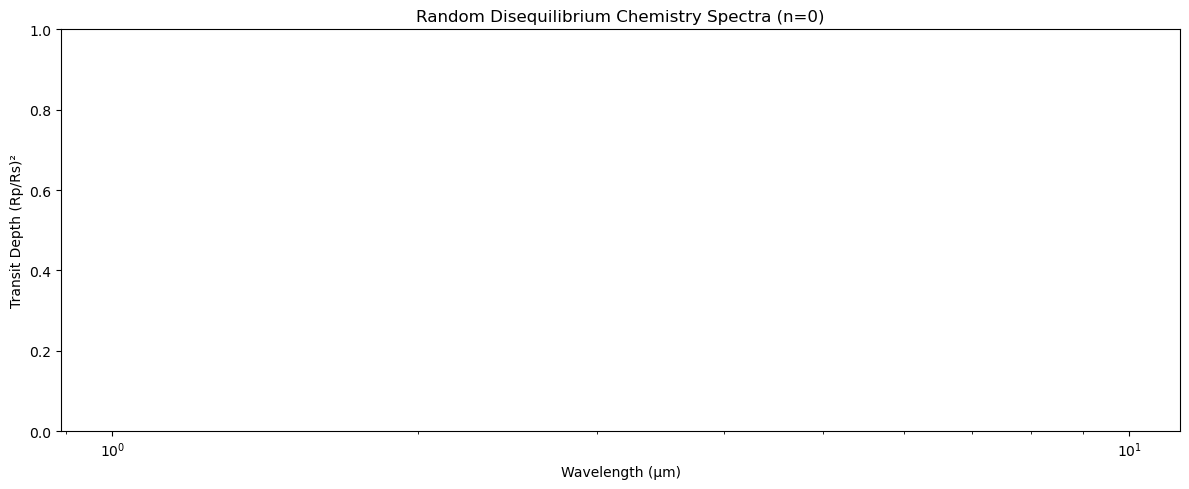

In [9]:
idx = np.random.choice(len(spectra_arr), min(20, len(spectra_arr)), replace=False)

fig, ax = plt.subplots(figsize=(12, 5))
for i in idx:
    ax.plot(wl_binned, spectra_arr[i], alpha=0.6, linewidth=1)

ax.set_xlabel("Wavelength (μm)")
ax.set_ylabel("Transit Depth (Rp/Rs)²")
ax.set_title(f"Random Disequilibrium Chemistry Spectra (n={len(spectra_arr)})")
ax.set_xscale("log")
plt.tight_layout()
plt.show()

In [10]:
import matplotlib.ticker as mticker
# Z-score normalise each spectrum by its own mean and std
epsilon = 1e-8   # prevents division by zero for flat spectra

spectra_mean = spectra_arr.mean(axis=1, keepdims=True)   # shape (N, 1)
spectra_std  = spectra_arr.std(axis=1, keepdims=True)    # shape (N, 1)

spectra_norm = (spectra_arr - spectra_mean) / (spectra_std + epsilon)

print(f"Normalised spectra shape : {spectra_norm.shape}")
print(f"Mean of normalised (should be ~0) : {spectra_norm.mean():.4f}")
print(f"Std  of normalised (should be ~1) : {spectra_norm.std():.4f}")

# Plot
idx = np.random.choice(len(spectra_norm), min(10, len(spectra_norm)), replace=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Left — raw spectra
for i in idx:
    axes[0].plot(wl_binned, spectra_arr[i], alpha=0.6, linewidth=1)
axes[0].set_xlabel("Wavelength (μm)")
axes[0].set_ylabel("Transit Depth (Rp/Rs)²")
axes[0].set_title("Raw Disequilibrium Spectra")


# Right — normalised spectra
for i in idx:
    axes[1].plot(wl_binned, spectra_norm[i], alpha=0.5, linewidth=1)
axes[1].set_xlabel("Wavelength (μm)")
axes[1].set_ylabel("Z-score Normalised Transit Depth")
axes[1].set_title("Z-score Normalised Disequilibrium Spectra")

axes[1].axhline(0, color="black", linewidth=0.8, linestyle="--", alpha=0.4)


ticks = [0.6, 0.8, 1, 2, 3, 5, 7]  # choose values within your wavelength range

for ax in axes:
    ax.set_xscale("log")
    ax.set_xticks(ticks)
    ax.set_xticklabels([str(t) for t in ticks])
    ax.xaxis.set_minor_formatter(mticker.NullFormatter())

plt.suptitle("Raw vs Normalised — Disequilibrium Chemistry Spectra", fontsize=13)
plt.tight_layout()
plt.show()

AxisError: axis 1 is out of bounds for array of dimension 1

In [ ]:
print(wl_binned.min(), wl_binned.max())

0.55 7.2755592


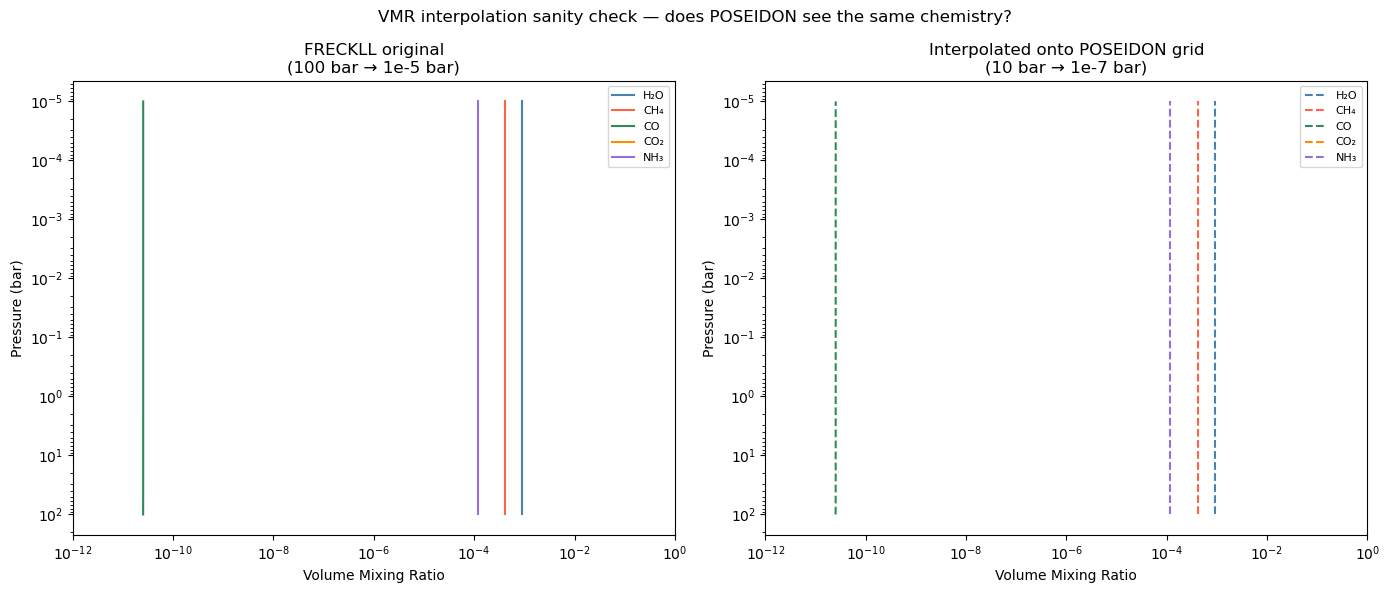

Using profile index 1: T=591K, log_Kzz=4.3
H₂O: FRECKLL range 6.09e-04–9.18e-04  |  POSEIDON range 6.09e-04–9.18e-04
CH₄: FRECKLL range 1.18e-04–4.20e-04  |  POSEIDON range 1.18e-04–4.20e-04
CO: FRECKLL range 1.59e-17–2.95e-04  |  POSEIDON range 1.59e-17–2.95e-04
CO₂: FRECKLL range 5.47e-19–6.72e-06  |  POSEIDON range 5.47e-19–6.72e-06
NH₃: FRECKLL range 3.03e-09–1.24e-04  |  POSEIDON range 3.03e-09–1.24e-04


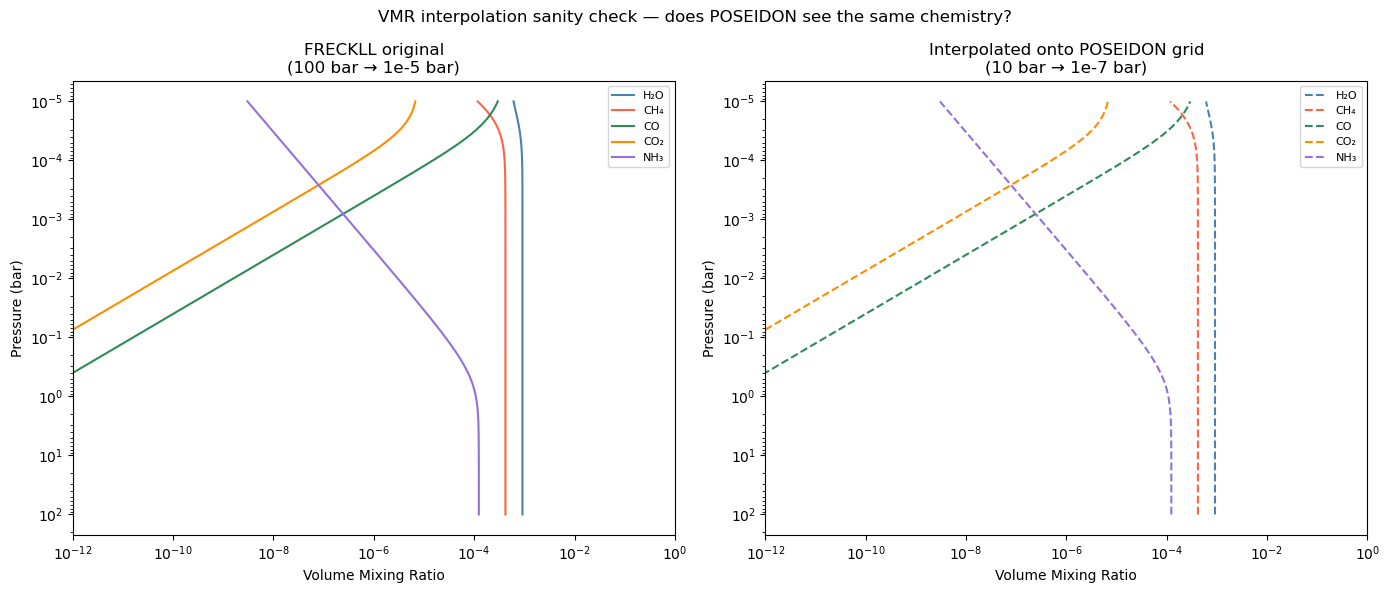


POSEIDON layers covered by FRECKLL grid : 100/100
Extrapolated layers (outside FRECKLL)   : 0
POSEIDON layers covered by FRECKLL grid : 100/100
Extrapolated layers (outside FRECKLL)   : 0
FRECKLL range  : 1.0e-05 → 1.0e+02 bar
POSEIDON range : 1.0e-05 → 1.0e+02 bar


In [ ]:
# VMR interpolation sanity check — FRECKLL grid vs POSEIDON grid
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

molecules  = [("h2o", "H₂O", "steelblue"), ("ch4", "CH₄", "tomato"),
              ("co",  "CO",  "seagreen"),   ("co2", "CO₂", "darkorange"),
              ("nh3", "NH₃", "mediumpurple")]

# Pick one example profile
example_row = df_final_clean.iloc[0]
example_data = np.load(example_row["path"])

for mol, label, color in molecules:
    vmr_original    = example_data[mol]           # on FRECKLL grid
    vmr_interpolated = interp_vmr(vmr_original)   # on POSEIDON grid (log10 space)
    vmr_interpolated = 10 ** vmr_interpolated      # back to linear

    axes[0].plot(vmr_original,    freckll_P, label=label, color=color, lw=1.5)
    axes[1].plot(vmr_interpolated, P,        label=label, color=color, lw=1.5, linestyle="--")

for ax, title, pressure in zip(axes,
    ["FRECKLL original\n(100 bar → 1e-5 bar)",
     "Interpolated onto POSEIDON grid\n(10 bar → 1e-7 bar)"],
    [freckll_P, P]):
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.invert_yaxis()
    ax.set_xlabel("Volume Mixing Ratio"); ax.set_ylabel("Pressure (bar)")
    ax.set_xlim(1e-12, 1e0); ax.legend(fontsize=8); ax.set_title(title)

plt.suptitle("VMR interpolation sanity check — does POSEIDON see the same chemistry?", fontsize=12)
plt.tight_layout(); plt.show()

# Quantify overlap
overlap = (P <= freckll_P[0]) & (P >= freckll_P[-1])# Fixed VMR interpolation sanity check

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

molecules = [("h2o", "H₂O", "steelblue"), ("ch4", "CH₄", "tomato"),
             ("co",  "CO",  "seagreen"),   ("co2", "CO₂", "darkorange"),
             ("nh3", "NH₃", "mediumpurple")]

# Try a few profiles until we find one with vertical structure
example_data = None
for i in range(len(df_final_clean)):
    row = df_final_clean.iloc[i]
    d = np.load(row["path"])
    # Check if H2O has any vertical variation
    if d["h2o"].std() > 1e-10:
        example_data = d
        example_row  = row
        print(f"Using profile index {i}: T={row['T']:.0f}K, log_Kzz={row['log_Kzz']:.1f}")
        break

if example_data is None:
    print("All profiles are flat! Using first one anyway.")
    example_data = np.load(df_final_clean.iloc[0]["path"])
    example_row  = df_final_clean.iloc[0]

# Plot
for mol, label, color in molecules:
    vmr_original     = example_data[mol]           # on FRECKLL grid, linear scale
    vmr_interp_log10 = interp_vmr(vmr_original)    # interp_vmr works in log10 space
    vmr_interpolated = 10 ** vmr_interp_log10       # convert back to linear

    print(f"{label}: FRECKLL range {vmr_original.min():.2e}–{vmr_original.max():.2e}  |  "
          f"POSEIDON range {vmr_interpolated.min():.2e}–{vmr_interpolated.max():.2e}")

    axes[0].plot(vmr_original,    freckll_P, label=label, color=color, lw=1.5)
    axes[1].plot(vmr_interpolated, P,        label=label, color=color, lw=1.5, linestyle="--")

for ax, title, pressure in zip(axes,
    ["FRECKLL original\n(100 bar → 1e-5 bar)",
     "Interpolated onto POSEIDON grid\n(10 bar → 1e-7 bar)"],
    [freckll_P, P]):
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.invert_yaxis()
    ax.set_xlabel("Volume Mixing Ratio"); ax.set_ylabel("Pressure (bar)")
    ax.set_xlim(1e-12, 1e0); ax.legend(fontsize=8); ax.set_title(title)

plt.suptitle("VMR interpolation sanity check — does POSEIDON see the same chemistry?", fontsize=12)
plt.tight_layout(); plt.show()

# Quantify overlap
overlap = (P <= freckll_P[0]) & (P >= freckll_P[-1])
print(f"\nPOSEIDON layers covered by FRECKLL grid : {overlap.sum()}/100")
print(f"Extrapolated layers (outside FRECKLL)   : {(~overlap).sum()}")
print(f"POSEIDON layers covered by FRECKLL grid : {overlap.sum()}/100")
print(f"Extrapolated layers (outside FRECKLL)   : {(~overlap).sum()}")
print(f"FRECKLL range  : {freckll_P[-1]:.1e} → {freckll_P[0]:.1e} bar")
print(f"POSEIDON range : {P[-1]:.1e} → {P[0]:.1e} bar")

In [ ]:
# Diagnostic cell — run this before anything else
import numpy as np

# Pick one profile
row = df_final_clean.iloc[1]
data = np.load(row["path"])

T, Rp, Mp = row.T, row.Rp_Rj, row.Mp_Mj

T_input = np.full(N_layers, T)
X_input = build_X_input(data["h2o"], data["ch4"], data["co"], data["co2"], data["nh3"])

print("T_input shape:", T_input.shape)
print("X_input shape:", X_input.shape)
print("P shape:", P.shape)
print("P range:", P.min(), "→", P.max())
print()

# Check each row of X_input
species = ["H2", "He", "H2O", "CH4", "CO", "CO2", "NH3"]
for i, name in enumerate(species):
    row_vals = X_input[i]
    print(f"{name}: min={row_vals.min():.3f}, max={row_vals.max():.3f}, "
          f"has_nan={np.any(np.isnan(row_vals))}, has_inf={np.any(np.isinf(row_vals))}")

ValueError: could not broadcast input array from shape (12,) into shape (100,)

In [ ]:
row  = df_final_clean.iloc[1]
data = np.load(row["path"])

print("h2o profile:")
print("  min:", data["h2o"].min())
print("  max:", data["h2o"].max())
print("  any nan:", np.any(np.isnan(data["h2o"])))
print("  any inf:", np.any(np.isinf(data["h2o"])))
print("  any negative:", np.any(data["h2o"] < 0))
print()
print("log10 of h2o:")
log_h2o = np.log10(np.clip(data["h2o"], 1e-300, None))
print("  min:", log_h2o.min())
print("  max:", log_h2o.max())
print("  any nan:", np.any(np.isnan(log_h2o)))

h2o profile:
  min: 0.0006089639298971561
  max: 0.0009182682493464919
  any nan: False
  any inf: False
  any negative: False

log10 of h2o:
  min: -3.215408430701366
  max: -3.0370304318781502
  any nan: False


In [ ]:
# Test with POSEIDON's original pressure range instead of FRECKLL's
P_poseidon = np.logspace(np.log10(10.0), np.log10(1e-7), N_layers)

print(f"Testing with POSEIDON native P range: {P_poseidon.max():.1e} → {P_poseidon.min():.1e} bar")

# Rerun with this pressure grid
atmosphere2 = make_atmosphere(planet, model, P_poseidon, P_ref, R_p_ref,
                               T_input=T_input, X_input=X_input)

spectrum2 = compute_spectrum(planet, star, model, atmosphere2, opac, wl_highres,
                              spectrum_type="transmission")

print("any nan:", np.any(np.isnan(spectrum2)))
print("min:", np.nanmin(spectrum2), "max:", np.nanmax(spectrum2))

Testing with POSEIDON native P range: 1.0e+01 → 1.0e-07 bar
any nan: True
min: nan max: nan


In [ ]:
# Check exactly what's going in to POSEIDON
species = ["H2", "He", "H2O", "CH4", "CO", "CO2", "NH3"]
print("X_input diagnostics (these are log10 values):")
for i, name in enumerate(species):
    vals = X_input[i]
    print(f"  {name}: min={vals.min():.3f}, max={vals.max():.3f}, "
          f"nan={np.any(np.isnan(vals))}, inf={np.any(np.isinf(vals))}, "
          f"linear_min={10**vals.min():.3e}, linear_max={10**vals.max():.3e}")

print()
print("Sum of linear VMRs at layer 0 (should be ~1.0):")
linear_sum = sum(10**X_input[i][0] for i in range(len(species)))
print(f"  {linear_sum:.4f}")

print()
print("Sum of linear VMRs at layer 50:")
linear_sum_mid = sum(10**X_input[i][50] for i in range(len(species)))
print(f"  {linear_sum_mid:.4f}")

X_input diagnostics (these are log10 values):
  H2: min=-0.081, max=-0.081, nan=False, inf=False, linear_min=8.300e-01, linear_max=8.300e-01
  He: min=-0.770, max=-0.770, nan=False, inf=False, linear_min=1.700e-01, linear_max=1.700e-01
  H2O: min=-3.215, max=-3.037, nan=False, inf=False, linear_min=6.090e-04, linear_max=9.183e-04
  CH4: min=-3.930, max=-3.377, nan=False, inf=False, linear_min=1.175e-04, linear_max=4.197e-04
  CO: min=-16.798, max=-3.530, nan=False, inf=False, linear_min=1.593e-17, linear_max=2.952e-04
  CO2: min=-18.262, max=-5.173, nan=False, inf=False, linear_min=5.472e-19, linear_max=6.722e-06
  NH3: min=-8.519, max=-3.907, nan=False, inf=False, linear_min=3.026e-09, linear_max=1.239e-04

Sum of linear VMRs at layer 0 (should be ~1.0):
  1.0015

Sum of linear VMRs at layer 50:
  1.0013


In [ ]:
# Check if opac was built on a different pressure grid
print("Opacity object keys:", opac.keys() if hasattr(opac, 'keys') else dir(opac))
print()

# Check what pressure grid the opacity was computed on
try:
    print("Opacity P grid:", opac['P'])
except:
    try:
        print("Opacity P grid:", opac.P)
    except:
        print("Can't access P directly, trying other attributes...")
        for attr in dir(opac):
            if 'press' in attr.lower() or attr == 'P':
                print(f"  {attr}:", getattr(opac, attr))

Opacity object keys: dict_keys(['opacity_database', 'opacity_treatment', 'sigma_stored', 'CIA_stored', 'Rayleigh_stored', 'eta_stored', 'ff_stored', 'bf_stored', 'T_fine', 'log_P_fine', 'database_version', 'aerosol_stored'])

Can't access P directly, trying other attributes...


In [ ]:
# Try computing spectrum with verbose errors
import warnings
warnings.filterwarnings('always')

try:
    spectrum3 = compute_spectrum(planet, star, model, atmosphere2, opac, wl_highres,
                                  spectrum_type="transmission")
    # Find where NaN first appears
    nan_channels = np.where(np.isnan(spectrum3))[0]
    print(f"NaN at {len(nan_channels)} wavelength channels")
    print(f"First NaN at channel {nan_channels[0]}, wl={wl_highres[nan_channels[0]]:.3f} μm")
    print(f"Last valid channel: {nan_channels[0]-1}, wl={wl_highres[nan_channels[0]-1]:.3f} μm")
    print(f"Are ALL channels NaN? {len(nan_channels) == len(spectrum3)}")
except Exception as e:
    print(f"Exception: {e}")
    import traceback
    traceback.print_exc()

NaN at 48283 wavelength channels
First NaN at channel 0, wl=0.400 μm
Last valid channel: -1, wl=10.000 μm
Are ALL channels NaN? True


In [ ]:
print("Opacity log_P_fine:", opac['log_P_fine'])
print("Range:", opac['log_P_fine'].min(), "→", opac['log_P_fine'].max())
print()
print("Our P grid log10:", np.log10(P_poseidon.min()), "→", np.log10(P_poseidon.max()))
print()

# Also check T_fine
print("Opacity T_fine range:", opac['T_fine'].min(), "→", opac['T_fine'].max())
print("Our T:", T)
print()

# Check if T=591K is within the opacity table range
if T < opac['T_fine'].min() or T > opac['T_fine'].max():
    print("⚠️  T IS OUTSIDE OPACITY TABLE RANGE!")
else:
    print("✓ T is within opacity table range")

Opacity log_P_fine: [-8.00000000e+00 -7.80000000e+00 -7.60000000e+00 -7.40000000e+00
 -7.20000000e+00 -7.00000000e+00 -6.80000000e+00 -6.60000000e+00
 -6.40000000e+00 -6.20000000e+00 -6.00000000e+00 -5.80000000e+00
 -5.60000000e+00 -5.40000000e+00 -5.20000000e+00 -5.00000000e+00
 -4.80000000e+00 -4.60000000e+00 -4.40000000e+00 -4.20000000e+00
 -4.00000000e+00 -3.80000000e+00 -3.60000000e+00 -3.40000000e+00
 -3.20000000e+00 -3.00000000e+00 -2.80000000e+00 -2.60000000e+00
 -2.40000000e+00 -2.20000000e+00 -2.00000000e+00 -1.80000000e+00
 -1.60000000e+00 -1.40000000e+00 -1.20000000e+00 -1.00000000e+00
 -8.00000000e-01 -6.00000000e-01 -4.00000000e-01 -2.00000000e-01
  7.10542736e-15  2.00000000e-01  4.00000000e-01  6.00000000e-01
  8.00000000e-01  1.00000000e+00  1.20000000e+00  1.40000000e+00
  1.60000000e+00  1.80000000e+00  2.00000000e+00]
Range: -8.0 → 2.000000000000009

Our P grid log10: -7.0 → 1.0

Opacity T_fine range: 300 → 3000
Our T: 591.3579304908001

✓ T is within opacity table 

In [ ]:
# Check how Dataset A passed X_input
# In Dataset A, chemistry came from load_chemistry_grid which returns
# abundances in a specific format. Let's check what POSEIDON actually expects.

print("atmosphere2 keys or attributes:")
print(type(atmosphere2))

# Check what's inside the atmosphere object
if hasattr(atmosphere2, '__dict__'):
    for k, v in atmosphere2.__dict__.items():
        if hasattr(v, 'shape'):
            print(f"  {k}: shape={v.shape}, min={np.nanmin(v):.3e}, max={np.nanmax(v):.3e}, nan={np.any(np.isnan(v))}")
        else:
            print(f"  {k}: {v}")
elif hasattr(atmosphere2, 'keys'):
    for k in atmosphere2.keys():
        v = atmosphere2[k]
        if hasattr(v, 'shape'):
            print(f"  {k}: shape={v.shape}, min={np.nanmin(v):.3e}, max={np.nanmax(v):.3e}, nan={np.any(np.isnan(v))}")
        else:
            print(f"  {k}: {v}")

atmosphere2 keys or attributes:
<class 'dict'>
  P: shape=(100,), min=1.000e-07, max=1.000e+01, nan=False
  T: 0
  g: shape=(), min=1.122e+01, max=1.122e+01, nan=False
  n: 0
  r: 0
  r_up: 0
  r_low: 0
  dr: 0
  P_surf: 1000
  X: 0
  X_active: 0
  X_CIA: 0
  X_ff: 0
  X_bf: 0
  mu: 0
  N_sectors: 1
  N_zones: 1
  alpha: 0.0
  beta: 0.0
  phi: shape=(1,), min=0.000e+00, max=0.000e+00, nan=False
  theta: shape=(1,), min=0.000e+00, max=0.000e+00, nan=False
  phi_edge: shape=(2,), min=-1.571e+00, max=1.571e+00, nan=False
  theta_edge: shape=(2,), min=-1.571e+00, max=1.571e+00, nan=False
  dphi: shape=(1,), min=3.142e+00, max=3.142e+00, nan=False
  dtheta: shape=(1,), min=3.142e+00, max=3.142e+00, nan=False
  kappa_cloud_0: 1e+250
  P_cloud: 100.0
  f_cloud: 0.0
  phi_cloud_0: -90.0
  theta_cloud_0: 90.0
  a: 1.0
  gamma: -4.0
  is_physical: False
  mu_back: None
  H: 0
  r_m: []
  log_n_max: 0
  fractional_scale_height: 0
  aerosol_species: []
  r_i_real: 0
  r_i_complex: 0
  log_X_Mie: [

In [ ]:
# Compare X_input format against what Dataset A produced
# In Dataset A what did make_atmosphere receive?
# Let's check the equi_chem_spectra.ipynb approach

# In Dataset A, X_profile was "file_read" with abundances as log10 mixing ratios
# The key question: does POSEIDON expect X_input in log10 or linear?

# Test: pass LINEAR values instead of log10
X_input_linear = np.array([
    np.full(N_layers, 0.83),           # H2 linear
    np.full(N_layers, 0.17),           # He linear
    data["h2o"],                        # H2O linear
    data["ch4"],                        # CH4 linear  
    data["co"],                         # CO linear
    data["co2"],                        # CO2 linear
    data["nh3"],                        # NH3 linear
])

atmosphere_linear = make_atmosphere(planet, model, P_poseidon, P_ref, R_p_ref,
                                     T_input=T_input, X_input=X_input_linear)

spectrum_linear = compute_spectrum(planet, star, model, atmosphere_linear, opac, wl_highres,
                                    spectrum_type="transmission")

print("Linear X_input — any nan:", np.any(np.isnan(spectrum_linear)))
print("min:", np.nanmin(spectrum_linear), "max:", np.nanmax(spectrum_linear))

Linear X_input — any nan: False
min: 0.03857621337951934 max: 0.040145781454475886


In [11]:
# Quick sanity check before anything else
row  = df_final_clean.iloc[1]
data = np.load(row["path"])

T  = row["T"]
Rp = row["Rp_Rj"]
Mp = row["Mp_Mj"]

T_input = np.full(N_layers, T)
X_input = build_X_input(data["h2o"], data["ch4"], data["co"], data["co2"], data["nh3"])

print("X_input[2] (H2O) — first 5 values:", X_input[2][:5])
print("Are these linear (should be ~0.0006) or log10 (should be ~-3.2)?")
print("Are these ones (should NOT be ~1.0)?")
print()

R_p    = Rp * R_J
M_p    = Mp * M_J
planet = create_planet("freckll_planet", R_p, mass=M_p, T_eq=T)

atm = make_atmosphere(planet, model, P_poseidon, 10.0, R_p,
                       T_input=T_input, X_input=X_input)
print("is_physical:", atm["is_physical"])

spec = compute_spectrum(planet, star, model, atm, opac, wl_highres,
                         spectrum_type="transmission")
print("any nan:", np.any(np.isnan(spec)))

X_input[2] (H2O) — first 5 values: [0.00091827 0.00091827 0.00091827 0.00091827 0.00091827]
Are these linear (should be ~0.0006) or log10 (should be ~-3.2)?
Are these ones (should NOT be ~1.0)?



NameError: name 'P_poseidon' is not defined